# Build a heart disease model
Classroom workflow: explore, split, baseline, compare, select a threshold, test, explain, predict, save.

**Question:** Does a patient have heart disease (`HeartDisease = 1`) or not (`0`)? There are 11 predictors: 5 categories and 6 numbers. This is a classroom exercise; predictions are not medical advice.

The notebook runs independently and shows each step. Run it with the working directory set to `notebooks/`. `train_heart.py` repeats the training workflow in one command.

In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
)
from sklearn.inspection import permutation_importance

df = pd.read_csv('../data/heart/heart.csv')
TARGET = 'HeartDisease'
CATEGORIES = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
ZERO_MEANS_MISSING = ['RestingBP', 'Cholesterol']
NUMBERS = ['Age', 'FastingBS', 'MaxHR', 'Oldpeak']
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 1. Explore and check the data
Inspect types, class balance, duplicates, and values that look wrong before modeling.

In [2]:
print('Rows and columns:', df.shape)
df.info()
print('Duplicate rows:', df.duplicated().sum())
display(df.describe().T)
display(df[CATEGORIES].nunique().rename('categories'))
display(df[TARGET].value_counts().rename(index={0: 'no heart disease', 1: 'heart disease'}))
print('Zeros (not measured):')
display(df[ZERO_MEANS_MISSING].eq(0).sum())

Rows and columns: (918, 12)
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


Sex               2
ChestPainType     4
RestingECG        3
ExerciseAngina    2
ST_Slope          3
Name: categories, dtype: int64

HeartDisease
heart disease       508
no heart disease    410
Name: count, dtype: int64

Zeros (not measured):


RestingBP        1
Cholesterol    172
dtype: int64

pandas reports no empty cells, but **172 rows have `Cholesterol = 0`** and one has `RestingBP = 0`. Nobody has zero cholesterol or zero blood pressure, so these mean "not measured". Dropping 172 rows would lose almost a fifth of the data. Instead, the pipeline will replace them with the training median and add a yes/no column that remembers the value was missing. `Oldpeak` can legitimately be negative, so its negative values stay.

## 2. Reserve a stratified test set
Keep 20% aside with a fixed seed. Further target-based exploration uses only training rows, so final evaluation stays separate.

Train: 734 Test: 184


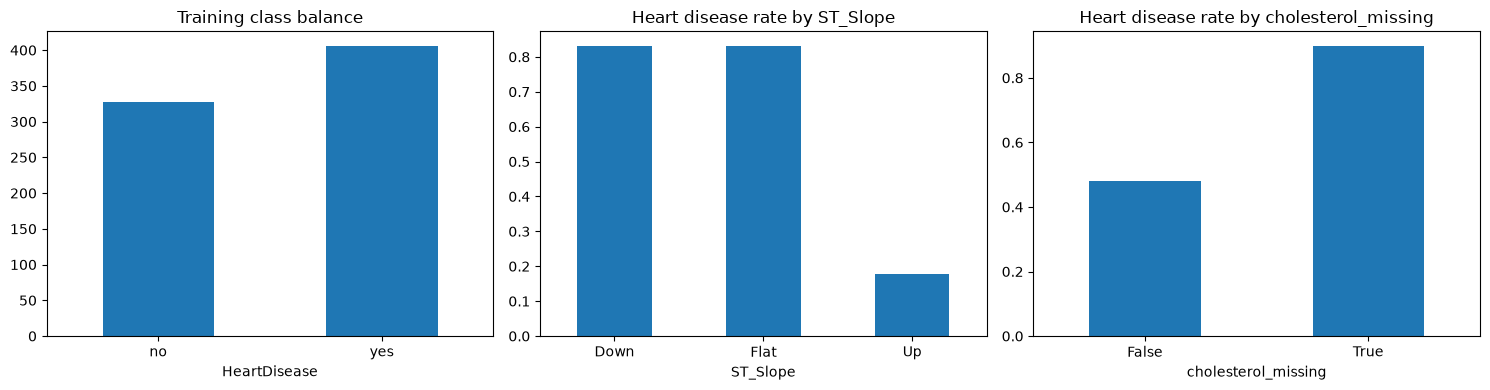

In [3]:
FEATURES = df.columns.drop(TARGET).tolist()
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
print('Train:', len(X_train), 'Test:', len(X_test))
explore = X_train.assign(heart_disease=y_train, cholesterol_missing=X_train['Cholesterol'].eq(0))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
y_train.value_counts().sort_index().rename(index={0: 'no', 1: 'yes'}).plot.bar(ax=axes[0], title='Training class balance', rot=0)
for ax, feature in zip(axes[1:], ['ST_Slope', 'cholesterol_missing']):
    explore.groupby(feature)['heart_disease'].mean().plot.bar(ax=ax, title=f'Heart disease rate by {feature}', rot=0)
plt.tight_layout(); plt.show()

Patients with missing cholesterol have heart disease much more often than the rest, so the "was missing" flag carries real information.

## 3. A baseline to beat
Always predict the training majority class. Accuracy alone can hide missed patients; report recall, precision, F1 and ROC AUC too.

In [4]:
majority = y_train.mode()[0]
baseline = accuracy_score(y_test, np.full(len(y_test), majority))
print(f'Majority baseline accuracy: {baseline:.4f}')

Majority baseline accuracy: 0.5543


## 4. Prepare the columns and compare three models
A `ColumnTransformer` treats each kind of column differently:
- `RestingBP`, `Cholesterol`: replace 0 with the median, add a missing flag, then scale.
- Other numbers: scale to a similar range (this matters for logistic regression).
- Categories: one-hot encode, so no false order is invented between codes.

The preprocessing sits inside each pipeline, so it is fitted inside each training fold. Compare logistic regression, a decision tree, and a random forest using five-fold ROC AUC. The test set is not used to select a model.

In [5]:
def preprocessing():
    return ColumnTransformer([
        ('missing', make_pipeline(SimpleImputer(missing_values=0, strategy='median', add_indicator=True), StandardScaler()), ZERO_MEANS_MISSING),
        ('numbers', StandardScaler(), NUMBERS),
        ('categories', OneHotEncoder(handle_unknown='ignore'), CATEGORIES),
    ])

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    'logistic regression': make_pipeline(preprocessing(), LogisticRegression(max_iter=2000, random_state=42)),
    'decision tree': make_pipeline(preprocessing(), DecisionTreeClassifier(max_depth=5, random_state=42)),
    'random forest': make_pipeline(preprocessing(), RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=1)),
}
scores = {}
rows = []
for name, candidate in models.items():
    auc = cross_val_score(candidate, X_train, y_train, cv=folds, scoring='roc_auc')
    scores[name] = float(auc.mean())
    rows.append({'model': name, 'mean ROC AUC': auc.mean(), 'std': auc.std()})
display(pd.DataFrame(rows).sort_values('mean ROC AUC', ascending=False))
best_name = max(scores, key=scores.get)
model = models[best_name]
print('Selected:', best_name)

,model,mean ROC AUC,std
2,random forest,0.928248,0.026960
0,logistic regression,0.928088,0.038899
1,decision tree,0.864097,0.040145


Selected: random forest


Logistic regression and random forest score almost the same. Either is a reasonable choice; the simpler logistic regression is easier to explain, while the random forest is slightly more stable across folds.

## 5. Choose a decision threshold on training data
Use out-of-fold probabilities: each training row is predicted by a model that did not fit that row. Maximize heart disease F1; choose the threshold nearest 0.5 on ties. A threshold below 0.5 flags more patients, which raises recall (fewer missed patients) at the cost of more false alarms.

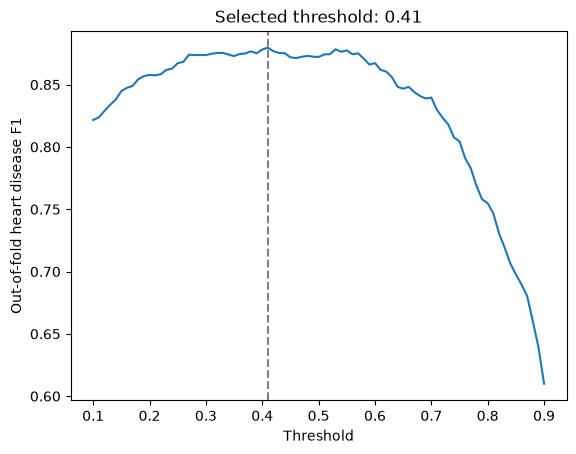

In [6]:
oof = cross_val_predict(model, X_train, y_train, cv=folds, method='predict_proba')[:, 1]
thresholds = np.round(np.arange(.1, .91, .01), 2)
f1s = np.array([f1_score(y_train, oof >= t) for t in thresholds])
tied = thresholds[np.isclose(f1s, f1s.max(), rtol=0, atol=1e-12)]
threshold = float(tied[np.argmin(abs(tied - .5))])
plt.plot(thresholds, f1s)
plt.axvline(threshold, linestyle='--', color='gray')
plt.xlabel('Threshold'); plt.ylabel('Out-of-fold heart disease F1')
plt.title(f'Selected threshold: {threshold}')
plt.show()

## 6. Fit and evaluate once on held-out data
Read the bottom-left confusion cell as missed heart disease patients: the dangerous mistake. Probability outputs are model estimates, not calibrated medical risk.

accuracy     0.891304
precision    0.866071
recall       0.950980
f1           0.906542
roc_auc      0.941356
dtype: float64

                  precision    recall  f1-score   support

no heart disease     0.9306    0.8171    0.8701        82
   heart disease     0.8661    0.9510    0.9065       102

        accuracy                         0.8913       184
       macro avg     0.8983    0.8840    0.8883       184
    weighted avg     0.8948    0.8913    0.8903       184



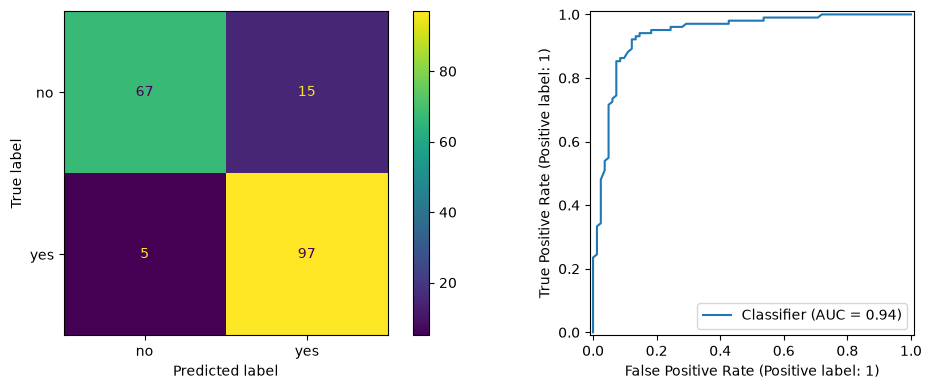

In [7]:
model.fit(X_train, y_train)
proba = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
predicted = proba >= threshold
metrics = {
    'accuracy': accuracy_score(y_test, predicted),
    'precision': precision_score(y_test, predicted, zero_division=0),
    'recall': recall_score(y_test, predicted, zero_division=0),
    'f1': f1_score(y_test, predicted, zero_division=0),
    'roc_auc': roc_auc_score(y_test, proba),
}
display(pd.Series(metrics))
print(classification_report(y_test, predicted, target_names=['no heart disease', 'heart disease'], digits=4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, predicted, display_labels=['no', 'yes'], ax=axes[0])
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1])
plt.tight_layout(); plt.show()

## 7. Which features matter?
Shuffle each original column and measure the drop in test ROC AUC. This explains the fitted model; do not use these test results to tune it. Correlated features can share importance.

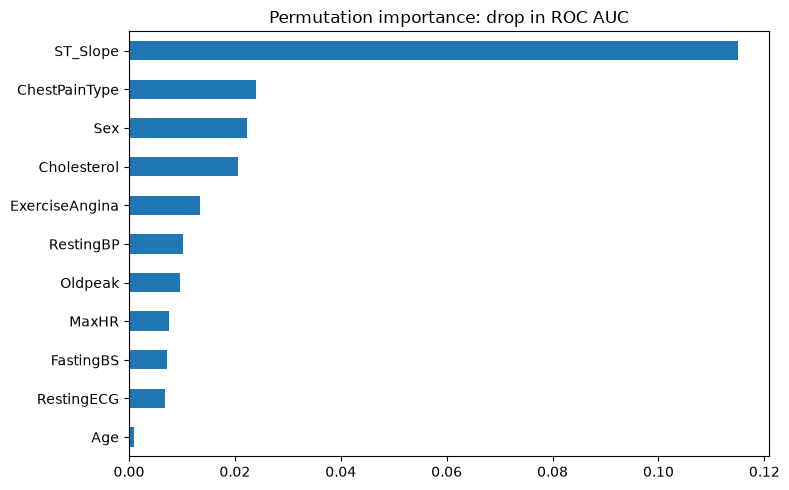

In [8]:
importance = permutation_importance(model, X_test, y_test, scoring='roc_auc', n_repeats=5, random_state=42, n_jobs=1)
pd.Series(importance.importances_mean, index=FEATURES).sort_values().plot.barh(figsize=(8, 5), title='Permutation importance: drop in ROC AUC')
plt.tight_layout(); plt.show()

## 8. Predict and inspect errors
Use real held-out rows in the same column order as the API. These are examples from the dataset, not independent clinical validation.

In [9]:
examples = X_test.head(5)
display(examples.assign(actual=y_test.head(5).map({0: 'no', 1: 'yes'}), heart_disease_probability=model.predict_proba(examples)[:, 1].round(3)))
mistakes = X_test.assign(actual=y_test, predicted=predicted.astype(int), probability=proba.round(3))[y_test != predicted]
print('Errors:', len(mistakes))
display(mistakes.head(10))

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,actual,heart_disease_probability
356,46,M,ASY,115,0,0,Normal,113,Y,1.5,Flat,yes,0.980
763,58,M,NAP,132,224,0,LVH,173,N,3.2,Up,yes,0.283
817,60,M,ASY,125,258,0,LVH,141,Y,2.8,Flat,yes,0.950
735,49,M,NAP,120,188,0,Normal,139,N,2.0,Flat,yes,0.623
892,39,F,NAP,138,220,0,Normal,152,N,0.0,Flat,no,0.283


Errors: 20


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,actual,predicted,probability
763,58,M,NAP,132,224,0,LVH,173,N,3.2,Up,1,0,0.283
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1,0,0.313
840,41,M,ATA,135,203,0,Normal,132,N,0.0,Flat,0,1,0.753
21,44,M,ATA,120,184,0,Normal,142,N,1.0,Flat,0,1,0.587
314,53,M,ASY,80,0,0,Normal,141,Y,2.0,Down,0,1,0.870
698,41,M,NAP,130,214,0,LVH,168,N,2.0,Flat,0,1,0.460
605,51,F,ASY,114,258,1,LVH,96,N,1.0,Up,0,1,0.420
307,53,M,ATA,130,0,0,ST,120,N,0.7,Down,0,1,0.600
636,48,M,ATA,130,245,0,LVH,180,N,0.2,Flat,0,1,0.563
724,45,F,ATA,112,160,0,Normal,138,N,0.0,Flat,0,1,0.413


## 9. Save the pipeline and metadata for FastAPI
Save the preprocessing with the classifier, column order, threshold, held-out metrics, CV scores and library version. The API loads this bundle once at startup. Only load trusted joblib files.

In [10]:
bundle = {
    'model': model,
    'algorithm': best_name,
    'features': FEATURES,
    'threshold': threshold,
    'metrics': {k: round(float(v), 4) for k, v in metrics.items()},
    'cv_scores': scores,
    'baseline_accuracy': float(baseline),
    'labels': {0: 'no heart disease', 1: 'heart disease'},
    'trained_at': pd.Timestamp.now(tz='UTC').isoformat(timespec='seconds'),
    'sklearn_version': sklearn.__version__,
}
Path('../models').mkdir(exist_ok=True)
joblib.dump(bundle, '../models/heart.joblib')
print('Saved: ../models/heart.joblib')

Saved: ../models/heart.joblib
